# 3. SupportSense — Retrieval & RAG Modeling
## Business question: Can the assistant retrieve approved evidence and handle uncertainty safely?

A support assistant is only useful if it retrieves the right policy or troubleshooting article. This notebook establishes a transparent TF–IDF retrieval baseline, evaluates source ranking against the benchmark's expected document labels, inspects failure cases, and tests a retrieval-confidence threshold for abstention.

**Decision focus:** identify whether the current retrieval baseline is ready for a larger human-reviewed evaluation—not claim production readiness from 12 questions.

## 1. Load the corpus and benchmark
Load the same curated knowledge base and evaluation questions used by the earlier notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / "data" / "company_docs.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from project root or notebooks/ folder.")
docs = json.loads((ROOT / "data" / "company_docs.json").read_text(encoding="utf-8"))
questions = pd.DataFrame(json.loads((ROOT / "data" / "evaluation_questions.json").read_text(encoding="utf-8")))
doc_texts = [d["title"] + " " + d["text"] for d in docs]
doc_ids = [d["doc_id"] for d in docs]
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
doc_matrix = vectorizer.fit_transform(doc_texts)
print(f"{len(docs)} approved documents | {len(questions)} benchmark questions")
display(questions[["question_id", "question", "expected_doc", "answerable"]].head())

10 approved documents | 12 benchmark questions


,question_id,question,expected_doc,answerable
0,Q01,How do I reset my password and how long does t...,KB-001,True
1,Q02,Who can download an invoice?,KB-002,True
2,Q03,Can you guarantee an annual subscription refun...,KB-003,True
3,Q04,What should I do if our API returns HTTP 429?,KB-005,True
4,Q05,How long does a data export link remain valid?,KB-006,True


## 2. Define retrieval and ranking metrics
**Hit@k** checks whether the expected document appears in the top *k* results. **Reciprocal rank** rewards finding it near the top. Unanswerable questions have no expected document, so they are excluded from these ranking metrics and assessed separately.

In [2]:
def retrieve(question, k=3):
    q_vec = vectorizer.transform([question])
    scores = cosine_similarity(q_vec, doc_matrix).ravel()
    order = np.argsort(scores)[::-1][:k]
    return [{"doc_id": doc_ids[i], "title": docs[i]["title"], "text": docs[i]["text"],
             "score": float(scores[i])} for i in order]

rows = []
for q in questions.to_dict("records"):
    ranked = retrieve(q["question"], k=len(docs))
    expected = q.get("expected_doc")
    ranks = [i+1 for i,d in enumerate(ranked) if expected and d["doc_id"] == expected]
    rows.append({
        "question_id": q["question_id"], "question": q["question"],
        "answerable": bool(q["answerable"]), "expected_doc": expected,
        "top1_doc": ranked[0]["doc_id"] if ranked else None,
        "top1_score": ranked[0]["score"] if ranked else 0.0,
        "expected_rank": ranks[0] if ranks else np.nan,
        "hit_at_1": int(bool(ranks) and ranks[0] <= 1),
        "hit_at_3": int(bool(ranks) and ranks[0] <= 3),
        "reciprocal_rank": 1/ranks[0] if ranks else 0.0,
        "top3_docs": ", ".join(d["doc_id"] for d in ranked[:3])
    })
retrieval_eval = pd.DataFrame(rows)
display(retrieval_eval)

,question_id,question,answerable,expected_doc,top1_doc,top1_score,expected_rank,hit_at_1,hit_at_3,reciprocal_rank,top3_docs
0,Q01,How do I reset my password and how long does t...,True,KB-001,KB-001,0.529510,1.0,1,1,1.0,"KB-001, KB-010, KB-009"
1,Q02,Who can download an invoice?,True,KB-002,KB-002,0.174012,1.0,1,1,1.0,"KB-002, KB-010, KB-009"
2,Q03,Can you guarantee an annual subscription refun...,True,KB-003,KB-003,0.299291,1.0,1,1,1.0,"KB-003, KB-009, KB-010"
3,Q04,What should I do if our API returns HTTP 429?,True,KB-005,KB-005,0.294144,1.0,1,1,1.0,"KB-005, KB-010, KB-009"
4,Q05,How long does a data export link remain valid?,True,KB-006,KB-006,0.554366,1.0,1,1,1.0,"KB-006, KB-001, KB-009"
5,Q06,Can support bypass workspace permissions to ma...,True,KB-008,KB-008,0.460117,1.0,1,1,1.0,"KB-008, KB-009, KB-010"
6,Q07,What is the standard API request limit?,True,KB-005,KB-005,0.329130,1.0,1,1,1.0,"KB-005, KB-010, KB-003"
7,Q08,Where can I enable two-factor authentication?,True,KB-004,KB-004,0.691311,1.0,1,1,1.0,"KB-004, KB-010, KB-009"
8,Q09,Does Northstar Cloud currently have a global o...,False,NaN,KB-007,0.279889,NaN,0,0,0.0,"KB-007, KB-001, KB-009"
9,Q10,What is the exact date my refund will arrive?,False,NaN,KB-003,0.388790,NaN,0,0,0.0,"KB-003, KB-010, KB-009"


## 3. Overall retrieval performance
Report ranking metrics only for answerable questions with an expected source. With a tiny benchmark, individual cases matter more than a single aggregate score.

,metric,value
0,Hit@1,0.90
1,Hit@3,1.00
2,Mean reciprocal rank,0.95


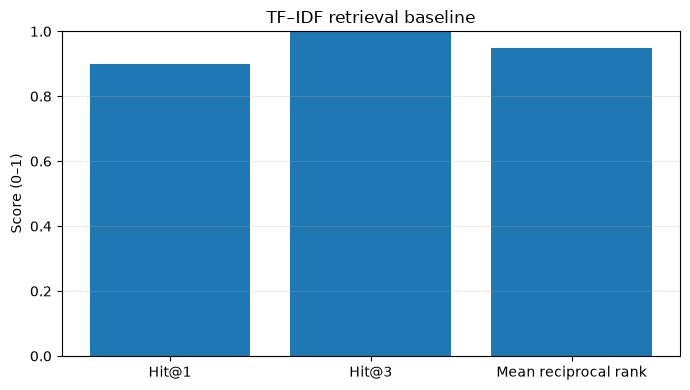

In [3]:
rankable = retrieval_eval[retrieval_eval["answerable"] & retrieval_eval["expected_doc"].notna()]
metrics = pd.DataFrame({
    "metric": ["Hit@1", "Hit@3", "Mean reciprocal rank"],
    "value": [rankable["hit_at_1"].mean(), rankable["hit_at_3"].mean(), rankable["reciprocal_rank"].mean()]
})
metrics["value"] = metrics["value"].round(3)
display(metrics)
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(metrics["metric"], metrics["value"])
ax.set_ylim(0,1)
ax.set_title("TF–IDF retrieval baseline")
ax.set_ylabel("Score (0–1)")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

## 4. Inspect failure cases and ranking margins
A retrieval failure can arise from ambiguous wording, vocabulary mismatch, or gaps in the corpus. Review each failure before changing the model; do not tune only to the current 12 examples.

In [4]:
failures = retrieval_eval[retrieval_eval["answerable"] & retrieval_eval["expected_doc"].notna() & (retrieval_eval["hit_at_1"] == 0)]
print(f"Answerable questions where expected document was not ranked first: {len(failures)}")
display(failures[["question_id","question","expected_doc","top1_doc","top1_score","expected_rank","top3_docs"]])

Answerable questions where expected document was not ranked first: 1


,question_id,question,expected_doc,top1_doc,top1_score,expected_rank,top3_docs
11,Q12,Can I send my one-time code to support to reco...,KB-001,KB-010,0.202286,2.0,"KB-010, KB-001, KB-008"


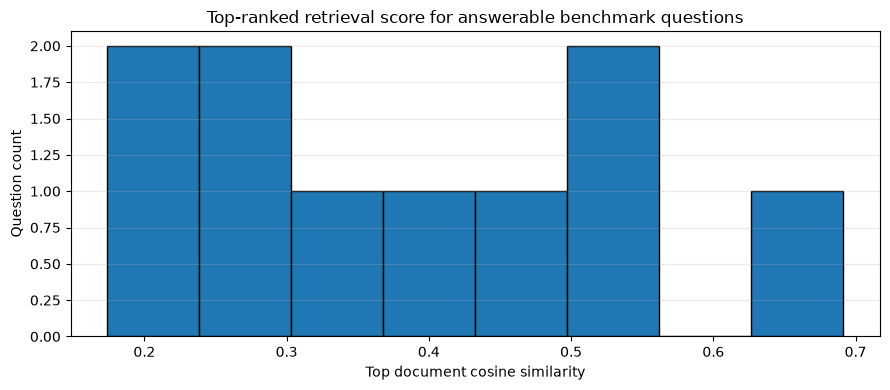

In [5]:
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(retrieval_eval.loc[retrieval_eval["answerable"], "top1_score"], bins=8, edgecolor="black")
ax.set_title("Top-ranked retrieval score for answerable benchmark questions")
ax.set_xlabel("Top document cosine similarity")
ax.set_ylabel("Question count")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

## 5. Test a confidence threshold for unanswerable questions
A threshold can reduce unsupported answers, but it may also cause unnecessary abstentions. We compare the top retrieval score to a small grid of thresholds. Because only two examples are labelled unanswerable, these results are exploratory.

,threshold,correct_abstention_rate,unnecessary_abstention_rate,answer_coverage
0,0.00,0.0,0.0,1.000
1,0.05,0.0,0.0,1.000
2,0.08,0.0,0.0,1.000
3,0.12,0.0,0.0,1.000
4,0.18,0.0,0.1,0.917
5,0.25,0.0,0.2,0.833


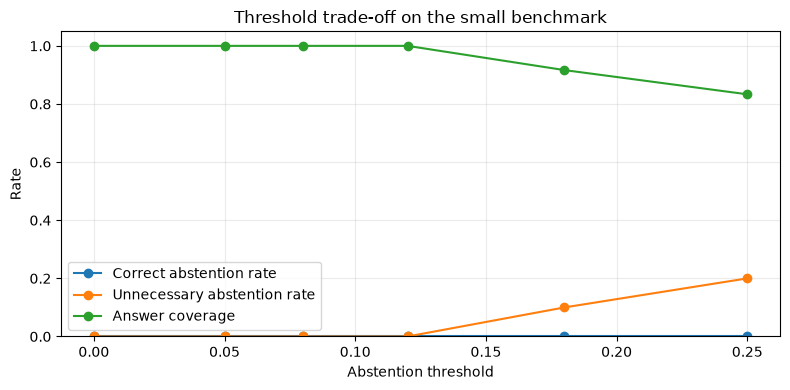

In [6]:
threshold_rows=[]
for threshold in [0.00, 0.05, 0.08, 0.12, 0.18, 0.25]:
    pred_abstain = retrieval_eval["top1_score"] < threshold
    actual_unanswerable = ~retrieval_eval["answerable"]
    threshold_rows.append({
        "threshold": threshold,
        "correct_abstention_rate": ((pred_abstain & actual_unanswerable).sum() / max(actual_unanswerable.sum(),1)),
        "unnecessary_abstention_rate": ((pred_abstain & ~actual_unanswerable).sum() / max((~actual_unanswerable).sum(),1)),
        "answer_coverage": (~pred_abstain).mean()
    })
threshold_eval=pd.DataFrame(threshold_rows)
display(threshold_eval.round(3))
fig, ax=plt.subplots(figsize=(8,4))
ax.plot(threshold_eval["threshold"], threshold_eval["correct_abstention_rate"], marker="o", label="Correct abstention rate")
ax.plot(threshold_eval["threshold"], threshold_eval["unnecessary_abstention_rate"], marker="o", label="Unnecessary abstention rate")
ax.plot(threshold_eval["threshold"], threshold_eval["answer_coverage"], marker="o", label="Answer coverage")
ax.set_title("Threshold trade-off on the small benchmark")
ax.set_xlabel("Abstention threshold")
ax.set_ylabel("Rate")
ax.set_ylim(0,1.05)
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 6. Export the retrieval evaluation
This file is an auditable input for the experiment notebook. Expected labels are used only for evaluation, never for retrieving or generating the answer.

In [7]:
outdir = ROOT / "data" / "processed"
outdir.mkdir(parents=True, exist_ok=True)
retrieval_eval.to_csv(outdir / "retrieval_evaluation.csv", index=False)
threshold_eval.to_csv(outdir / "abstention_threshold_sensitivity.csv", index=False)
print("Saved retrieval_evaluation.csv and abstention_threshold_sensitivity.csv to data/processed/")

Saved retrieval_evaluation.csv and abstention_threshold_sensitivity.csv to data/processed/


## 7. Findings and next decision

Use the computed tables above to report:
- how often the expected source is ranked first and within the top three;
- which questions fail and why;
- how changing the abstention threshold affects coverage and safety.

**Limitations:** TF–IDF is a lexical baseline, the corpus is synthetic and small, expected labels are hand-authored, and score thresholds are not calibrated probabilities. Do not call the top score a confidence probability.

**Recommendation:** expand the benchmark with expert-reviewed paraphrases, adversarial/unanswerable questions, and additional documents; then compare alternative retrievers on a held-out set before any production claim.

**Next notebook:** *A/B Experiment Analysis*, which compares a baseline response policy and an abstention-aware RAG policy on the same benchmark cases.